<a href="https://colab.research.google.com/github/fischdakid/is-4487-labs/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 11: Predicting Airbnb Prices with Regression

In this assignment, you will:
- Load the Airbnb dataset you cleaned and transformed in Assignment 7
- Build a linear regression model to predict listing price
- Interpret which features most affect price
- Try to improve your model using only the most impactful predictors
- Practice explaining your findings to a business audience like a host, pricing strategist, or city partner

## Why This Matters

Pricing is one of the most important levers for hosts and Airbnb’s business teams. Understanding what drives price — and being able to predict it accurately — helps improve search results, revenue management, and guest satisfaction.

This assignment gives you hands-on practice turning a cleaned dataset into a predictive model. You’ll focus not just on code, but on what the results mean and how you’d communicate them to stakeholders.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_11_regression.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Original Source: Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


## 1. Load Your Transformed Airbnb Dataset

**Business framing:**  
Before building any models, we must start with clean, prepared data. In Assignment 7, you exported a cleaned version of your Airbnb dataset. You’ll now import that file for analysis.

### Do the following:
- Import your CSV file called `cleaned_airbnb_data_7.csv`.   (Note: If you had significant errors with assignment 7, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)
- Use `pandas` to load and preview the dataset


In [2]:
# Load the cleaned file from Assignment 7 if it's uploaded; otherwise use the backup dataset on GitHub
import os
if os.path.exists('cleaned_airbnb_data_7.csv'):
    df = pd.read_csv('cleaned_airbnb_data_7.csv')
else:
    url = 'https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/airbnb_listings.csv'
    df = pd.read_csv(url)

print(df.shape)
df.head()

(459, 77)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,host_url,host_name,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20250804133828,2025-08-04,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://www.airbnb.com/users/show/4621559,Kenneth,...,4.56,3.22,3.67,NaN,0,1,1,0,0,0.07
1,3820211,https://www.airbnb.com/rooms/3820211,20250804133828,2025-08-04,city scrape,Funky Urban Gem: Prime Central Location - Park...,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.81,4.81,4.77,NaN,0,4,4,0,0,2.32
2,5651579,https://www.airbnb.com/rooms/5651579,20250804133828,2025-08-04,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",The neighborhood is very eclectic. We have a v...,https://www.airbnb.com/users/show/29288920,Gregg,...,4.88,4.76,4.64,NaN,0,2,1,1,0,2.97
3,6623339,https://www.airbnb.com/rooms/6623339,20250804133828,2025-08-04,city scrape,Bright & Cozy City Stay · Top Location + Parking!,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.70,4.80,4.72,NaN,0,4,4,0,0,2.68
4,9005989,https://www.airbnb.com/rooms/9005989,20250804133828,2025-08-04,city scrape,"Studio in The heart of Center SQ, in Albany NY",(21 years of age or older ONLY) NON- SMOKING.....,"There are many shops, restaurants, bars, museu...",https://www.airbnb.com/users/show/17766924,Sugey,...,4.93,4.87,4.77,NaN,0,1,1,0,0,5.67


### Reflection:
1. What business information does the dataset include?
2. How many rows and columns are present?

### ✍️ Your Response: 🔧
1. The business information that this datasewt covers is AirBnb Listings with the host details. Covering things from response rate, superhost, property features like room type, and all sorts of things. This is all he information the pricing teams need to see what drives nightly price.

2. The raw dataset is 459 rows and 77 columns. After cleaning the data and removing things it comes down to 417 rows and 36 columns that are the most important.

## 2. Drop Columns Not Useful for Modeling

**Business framing:**  
Some columns — like post IDs or text — may not help us predict price and could add noise or bias.

### Do the following:
- Drop columns like `post_id`, `title`, `descr`, `details`, and `address` if they’re still in your dataset

In [3]:
# Drop IDs, free text, URLs, and columns that leak price (estimated revenue = price x occupancy)
drop_cols = ['post_id', 'title', 'descr', 'details', 'address',
             'id', 'scrape_id', 'host_id', 'license', 'latitude', 'longitude',
             'estimated_revenue_l365d',
             'calculated_host_listings_count_entire_homes',
             'calculated_host_listings_count_private_rooms',
             'calculated_host_listings_count_shared_rooms']
df_model = df.drop(columns=[c for c in drop_cols if c in df.columns])

# Turn room_type into a 0/1 column so the model can use it
if 'room_type' in df_model.columns:
    df_model = pd.get_dummies(df_model, columns=['room_type'], drop_first=True, dtype=int)

# Keep numeric columns only (text like name/description/amenities can't go into linear regression)
df_model = df_model.select_dtypes('number').dropna(subset=['price'])

# Drop mostly-empty columns, fill remaining gaps with the median
df_model = df_model.loc[:, df_model.isna().mean() < 0.5]
df_model = df_model.fillna(df_model.median())

# Remove extreme price outliers (IQR rule) so a few luxury listings don't dominate the fit
q1, q3 = df_model['price'].quantile([0.25, 0.75])
price_cap = q3 + 1.5 * (q3 - q1)
df_model = df_model[df_model['price'] <= price_cap]

print('Price cap:', price_cap)
print('Shape after cleaning:', df_model.shape)
print(list(df_model.columns))

Price cap: 193.0
Shape after cleaning: (417, 36)
['host_listings_count', 'host_total_listings_count', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'price', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'instant_bookable', 'calculated_host_listings_count', 'reviews_per_month', 'room_type_Private room']


### Reflection:
1. What columns did you drop, and why?
2. What risks might occur if you included them in your model?

### ✍️ Your Response: 🔧
1. I dropped the IDsm URLS, Free text, license, latitude/longitude, and the host listing breakdown columns. I also decided to go ahead and drop estimated revenue because the revenue is calculated based on teh price. All the things I dropped are not meanful in terms of numeric predictors.

2. Leaving un-needed variables can cause overfitting, and lots of other issues that lead to a less accurate model. It also can cause random patterns to be found that aren't needed for what I am looking for.

## 3. Explore Relationships Between Numeric Features

**Business framing:**  
Understanding how features relate to each other — and to the target — helps guide feature selection and modeling.

### Do the following:
- Generate a correlation matrix
- Identify which variables are strongly related to `price`

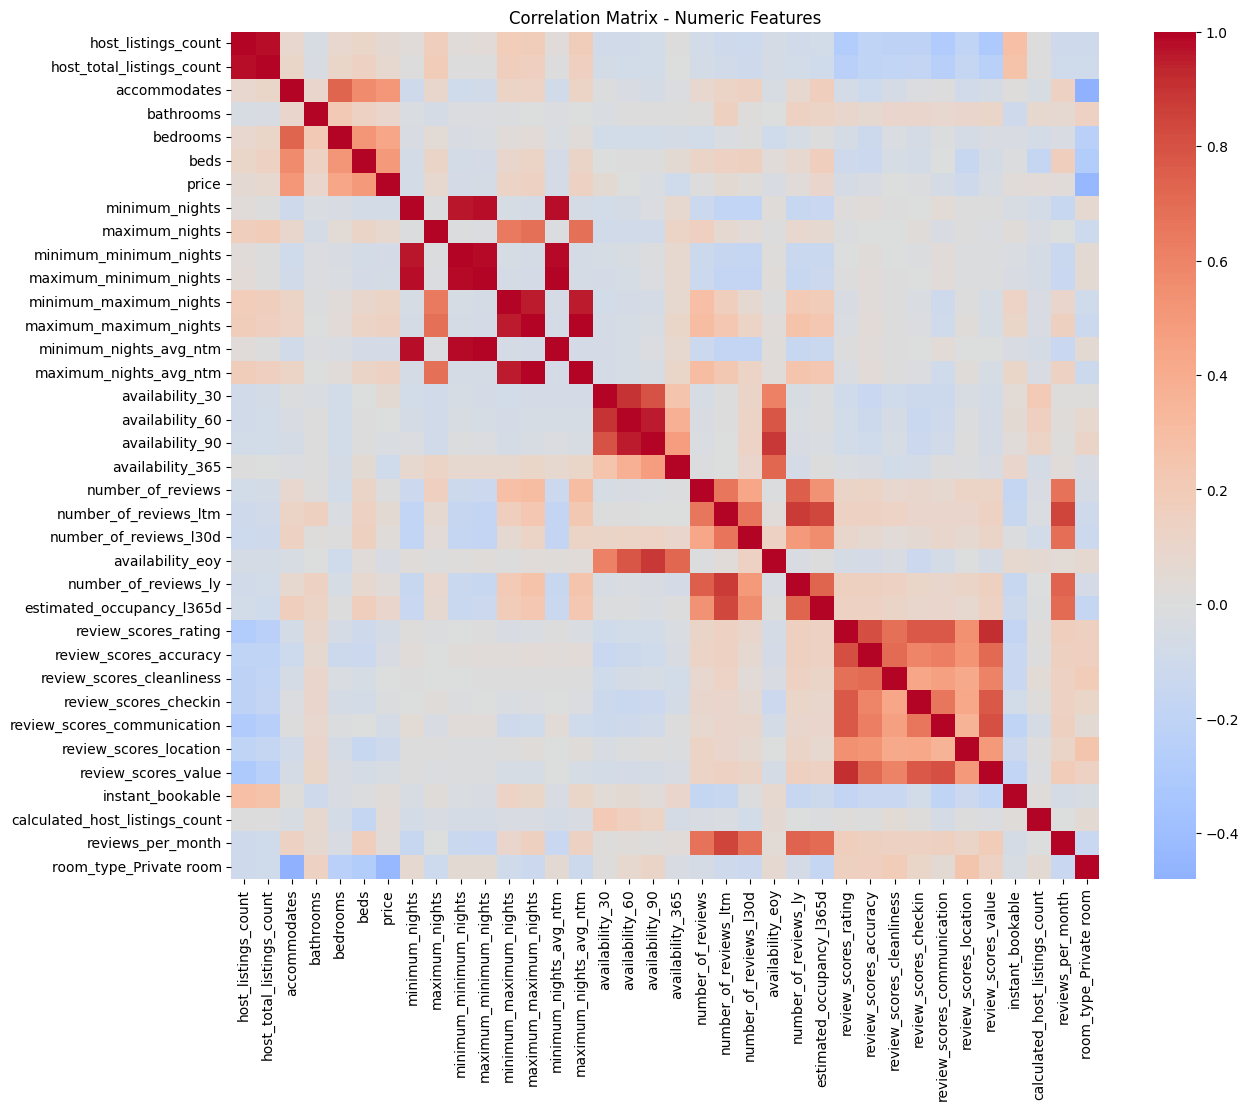

accommodates                 0.513451
beds                         0.494174
bedrooms                     0.439015
room_type_Private room      -0.437787
maximum_maximum_nights       0.137933
maximum_nights_avg_ntm       0.135819
minimum_maximum_nights       0.120614
estimated_occupancy_l365d    0.099493
review_scores_location      -0.098938
bathrooms                    0.094841
Name: price, dtype: float64


In [4]:
corr = df_model.corr()

plt.figure(figsize=(14, 11))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation Matrix - Numeric Features')
plt.show()

# Correlation of each feature with price, strongest first
price_corr = corr['price'].drop('price').sort_values(key=abs, ascending=False)
print(price_corr.head(10))

### Reflection:
1. Which variables had the strongest positive or negative correlation with price?
2. Which variables might be useful predictors?

### ✍️ Your Response: 🔧
1. The variables with the strongest positive correlation with price are accommadates, bedrooms, and beds. The variables with the strongest negative correlation were private rooms being that they are priced significantly lower than entire homes.

2. I found that the most valuable predictors for pricing are probably accommodates, beds, bedrooms, and bathrooms being that they are teh key features in a home and guest pay for size. These variables are also closely correlated with each other.

## 4. Define Features and Target Variable

**Business framing:**  
To build a regression model, you need to define what you’re predicting (target) and what you’re using to make that prediction (features).

### Do the following:
- Set `price` as your target variable
- Remove `price` from your predictors

In [5]:
y = df_model['price']
X = df_model.drop(columns='price')

print('Target: price')
print('Number of features:', X.shape[1])
print(list(X.columns))

Target: price
Number of features: 35
['host_listings_count', 'host_total_listings_count', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'minimum_nights', 'maximum_nights', 'minimum_minimum_nights', 'maximum_minimum_nights', 'minimum_maximum_nights', 'maximum_maximum_nights', 'minimum_nights_avg_ntm', 'maximum_nights_avg_ntm', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'availability_eoy', 'number_of_reviews_ly', 'estimated_occupancy_l365d', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'instant_bookable', 'calculated_host_listings_count', 'reviews_per_month', 'room_type_Private room']


### Reflection:
1. What features are you using?
2. Why is this a regression problem and not a classification problem?

### ✍️ Your Response: 🔧
1. I am going to use all of the remaining numeric features which is 35. These cover listings size, accommodates, bedrooms, beds, bathrooms, room type, etc. Being that price is the target I removed it from the predictors.

2. This is a regression problem rather than a classification problem because price is a continuous number that can be any given dollar amount. It's not a category. We are looking for the actual nightly price estimate so regression is the right approach.

## 5. Split Data into Training and Testing Sets

### Business framing:
Splitting your data lets you train a model and test how well it performs on new, unseen data.

### Do the following:
- Use `train_test_split()` to split into 80% training, 20% testing



In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (333, 35)  Test: (84, 35)


## 6. Fit a Linear Regression Model

### Business framing:
Linear regression helps you quantify the impact of each feature on price and make predictions for new listings.

### Do the following:
- Fit a linear regression model to your training data
- Use it to predict prices for the test set



In [7]:
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred[:5]

array([ 63.90939706,  91.14012367,  90.33457537, 134.50003235,
        91.26764121])

## 7. Evaluate Model Performance

### Business framing:  
A good model should make accurate predictions. We’ll use Mean Squared Error (MSE) and R² to evaluate how close our predictions were to the actual prices.

### Do the following:
- Print MSE and R² score for your model

In [8]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'MSE:  {mse:,.2f}')
print(f'RMSE: {mse ** 0.5:,.2f}  (average error in dollars)')
print(f'R2:   {r2:.3f}')

MSE:  559.59
RMSE: 23.66  (average error in dollars)
R2:   0.507


### Reflection:
1. What is your R² score? How well does your model explain price variation?
2. Is your MSE large or small? What could you do to improve it?

### ✍️ Your Response: 🔧
1. The R squared score is 0.507 which means the model explains around 50% of the price variation. This is a moderate fit. Size and Room type carry the model but other features aren't fully represented.

2. The MSE is 559.59 which which turns into an average error of 23.66. This is pretty large considering the fact that a typical listing is around 95 which means the model is around a 25% miss. I think to improve this I could ass neighborhood and amenity features along with dropping redundant variables.

## 8. Interpret Model Coefficients

### Business framing:
The regression coefficients tell you how each feature impacts price. This can help Airbnb guide hosts and partners.

### Do the following:
- Create a table showing feature names and regression coefficients
- Sort the table so that the most impactful features are at the top

In [9]:
coef_df = pd.DataFrame({'feature': X.columns, 'coefficient': model.coef_})
coef_df['abs_coefficient'] = coef_df['coefficient'].abs()
coef_df = coef_df.sort_values('abs_coefficient', ascending=False).reset_index(drop=True)
coef_df

,feature,coefficient,abs_coefficient
0,review_scores_communication,-23.950158,23.950158
1,room_type_Private room,-23.156294,23.156294
2,review_scores_accuracy,20.234445,20.234445
3,review_scores_checkin,18.366236,18.366236
4,review_scores_rating,-17.559093,17.559093
5,beds,11.405958,11.405958
6,minimum_nights_avg_ntm,6.787207,6.787207
7,maximum_minimum_nights,-6.553510,6.553510
8,review_scores_value,4.552156,4.552156
9,bathrooms,4.552066,4.552066


### Reflection:
1. Which features increased price the most?
2. Were any surprisingly negative?
3. What business insight could you draw from this?

### ✍️ Your Response: 🔧
1. Review accuracy, check in score, and beds have the largest coefficients. Bathrooms and value score did also add a couple dollars each.

2. The feature that is suprisingly negative to me is the communication score and overall ratings which are negative. I would expect better reviews to increase the price. I am guessing this is a multicollinearity. Things like private room being negative are expected.

3. I would tell host to charge more by adding sleeping capacity, extra beds, and listing entire homes instead of a private room. Having accurate listings and seamless check ins can support higher prices.


## 9. Try to Improve the Linear Regression Model

### Business framing:
The first version of your model included all available features — but not all features are equally useful. Removing weak or noisy predictors can often improve performance and interpretation.

### Do the following:
1. Choose your top 3–5 features with the strongest absolute coefficients
2. Rebuild the regression model using just those features
3. Compare MSE and R² between the baseline and refined model

In [10]:
# Keep the 5 features with the largest absolute coefficients
top_features = coef_df['feature'].head(5).tolist()
print('Top features:', top_features)

model_refined = LinearRegression()
model_refined.fit(X_train[top_features], y_train)
y_pred_refined = model_refined.predict(X_test[top_features])

mse_refined = mean_squared_error(y_test, y_pred_refined)
r2_refined = r2_score(y_test, y_pred_refined)

comparison = pd.DataFrame({
    'Model': ['Baseline (all features)', 'Refined (top 5)'],
    'MSE': [mse, mse_refined],
    'R2': [r2, r2_refined]
})
comparison

Top features: ['review_scores_communication', 'room_type_Private room', 'review_scores_accuracy', 'review_scores_checkin', 'review_scores_rating']


,Model,MSE,R2
0,Baseline (all features),559.585791,0.507033
1,Refined (top 5),998.388551,0.120470


### Reflection:
1. What features did you keep in the refined model, and why?
2. Did model performance improve? Why or why not?
3. Which model would you recommend to stakeholders?
4. How does this relate to your customized learning outcome you created in canvas?

### ✍️ Your Response: 🔧
1. For the refined model I kept the 5 features with the largest absolute coefficients. This being: communication score, private room, accuracy score, check in score, and overall rating. I did this based on the coefficient size.

2. The models performance actually decreased down to about 0.12. and the MSE rose up to 998. I think this is because review score barely vary and so the coefficents get inflated.

3. I would say to stick with the baseline model. It does a better job of explaining price variation and has a lower error. But I think having a better refined model that kept bedrooms, beds, and important features would do the best because it would be the most simple and accurate.

4. This relates directly to my learnign outcome of building and evaluating regression models against actual results. This assignment and lab gave me insight into making sure the simpler/refined model actual performs better or if its best to stay with the original. Testing models ties into my goal of demand forecasting.


## 10. Reflect and Recommend

### Business framing:  
Ultimately, the value of your model comes from how well it can guide business decisions. Use your results to make real-world recommendations.

### Reflection:
1. What business question did your model help answer?
2. What would you recommend to Airbnb or its hosts?
3. What could you do next to improve this model or make it more useful?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. This model answers the business question of which characteristics drive nightly price and how accurately we can predict a fair price for a listing. This is helpful for hosts and price setters int eh AirBnB industry.

2. I would recommend that hosts should price based on capacity. Adding in beds leads to higher rates. AirBnb could use this model as a starting point for pricing suggestions. Hosts should makes sure to still check with nearby comparible listings before setting the price.

3. I think to improve this model it would be helpful to add neighborhood, amenities, and seasonal demand data. It would also be important to drop redundant size and review variables trhat don't actuallt play an important role in setting the price. Maybe doing a random forest could be helpful to capture nonlinear effects.

4. My customized learnign outcomes focus on regression modeling and on communicating results to non-technical managers which is where things like this type of modeling come into play. This model could be helpful to hosts who have a little explanation that they can act on. This was a direct learning outcome of mine.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [12]:
!jupyter nbconvert --to html "assignment_11_regression.ipynb"

[NbConvertApp] Converting notebook assignment_11_regression.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 1 image(s).
[NbConvertApp] Writing 607727 bytes to assignment_11_regression.html
